# 01 – Explorácia datasetov

Kontrola pripravených dát: **Cresci-17** (`cresci_prepared.csv`) a **Unmasking the Imposters** (`unmasking_clean.csv`).

Očakávaná štruktúra:
```
data/processed/
├── cresci_prepared.csv
└── unmasking_clean.csv
```
Notebook nič netrénuje. Kontroluje počty, triedy, chýbajúce hodnoty, dĺžky textov, duplicity a **stĺpce, ktoré by prezradili triedu** (leak).

## 1. Import knižníc a cesty

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
CRESCI_FILE = DATA_DIR / "cresci_prepared.csv"
UNMASKING_FILE = DATA_DIR / "unmasking_clean.csv"

print("Projektový priečinok:", PROJECT_DIR)
print("Cresci súbor existuje:", CRESCI_FILE.exists())
print("Unmasking súbor existuje:", UNMASKING_FILE.exists())

Projektový priečinok: /Users/juraj/Documents/GitHub/bakalarska_praca/src
Cresci súbor existuje: True
Unmasking súbor existuje: True


# ČASŤ A – Cresci-17 (boty)

## 2. Načítanie

In [2]:
if not CRESCI_FILE.exists():
    raise FileNotFoundError(f"Nenašiel sa {CRESCI_FILE}. Najskôr spusti prepare_cresci.py.")

cresci = pd.read_csv(CRESCI_FILE, low_memory=False)
cresci_label_col = "label_name" if "label_name" in cresci.columns else "label"
print("Rozmer datasetu:", cresci.shape)
display(cresci.head(3))

Rozmer datasetu: (2074, 48)


,user_id,name,screen_name,statuses_count,followers_count,friends_count,favourites_count,listed_count,url,lang,...,crawled_at,updated,test_set_1,test_set_2,tweets_text,label,label_name,source,profile_text,text
0,191839658,pocahontas farida,wadespeters,202968,2248,981,60304,101,http://t.co/rGV0HIJGsu,en,...,2015-05-01 13:55:16,2016-03-15 15:53:48,0,0.0,RT @steviebuckys: do i look aesthetic yet http...,0,human,genuine_accounts,pocahontas farida wadespeters 20. menna: #fari...,pocahontas farida wadespeters 20. menna: #fari...
1,2157382005,JO,19_Joanne_87,12915,641,1066,1568,7,NaN,en,...,2015-05-01 13:46:12,2016-03-15 15:53:49,0,0.0,RT @BiblicalTweets_: A pocket full of cuteness...,0,human,genuine_accounts,JO 19_Joanne_87 CHRISTIAN -Communication degre...,JO 19_Joanne_87 CHRISTIAN -Communication degre...
2,1947320929,❄McKayla❄,1Dniallprincess,13676,1042,2000,19012,7,NaN,en,...,2015-05-01 13:35:33,2016-03-15 15:53:49,0,0.0,RT @TaylorBauerkemp: The worst feeling http://...,0,human,genuine_accounts,"❄McKayla❄ 1Dniallprincess Live, Young, Wild an...","❄McKayla❄ 1Dniallprincess Live, Young, Wild an..."


## 3. Rozdelenie tried

,počet účtov
label_name,
human,1083
bot,991


,počet
source,
genuine_accounts,1083
social_spambots_1,991


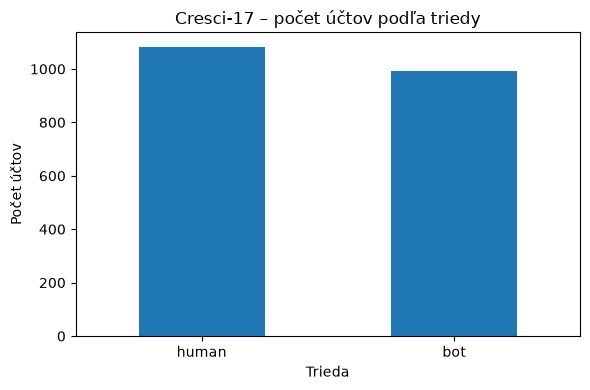

In [3]:
cresci_counts = cresci[cresci_label_col].value_counts(dropna=False)
display(cresci_counts.rename("počet účtov").to_frame())
if "source" in cresci.columns:
    display(cresci["source"].value_counts(dropna=False).rename("počet").to_frame())

ax = cresci_counts.plot(kind="bar", figsize=(6, 4))
ax.set_title("Cresci-17 – počet účtov podľa triedy")
ax.set_xlabel("Trieda"); ax.set_ylabel("Počet účtov")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. Duplicity a chýbajúce hodnoty v dôležitých stĺpcoch

In [4]:
print("Duplicitné user_id:", cresci["user_id"].duplicated().sum())

cresci["tweets_text"] = cresci["tweets_text"].fillna("").astype(str)
print("Účty s prázdnym tweets_text:", (cresci["tweets_text"].str.strip() == "").sum(), "(malo by byť 0)")

META_FEATURES = ["statuses_count", "followers_count", "friends_count",
                 "favourites_count", "listed_count"]
missing = cresci[META_FEATURES + ["created_at", "description"]].isna().sum()
display(missing.rename("chýbajúce").to_frame())

Duplicitné user_id: 0
Účty s prázdnym tweets_text: 0 (malo by byť 0)


,chýbajúce
statuses_count,0
followers_count,0
friends_count,0
favourites_count,0
listed_count,0
created_at,0
description,150


## 5. Stĺpce, ktoré prezrádzajú triedu (leak)

Tabuľka ukazuje, aký podiel riadkov má v každej triede vyplnenú hodnotu. Ak je rozdiel veľký (napr. 0.00 vs 1.00), stĺpec **nesmie** ísť do modelu. Do metadátového modelu používame len `META_FEATURES`.

In [5]:
shortcut_cols = [c for c in ["source", "label", "label_name", "test_set_1", "test_set_2",
                             "crawled_at", "timestamp", "updated"] if c in cresci.columns]
fill_rate = cresci.groupby(cresci_label_col)[shortcut_cols].agg(lambda s: s.notna().mean()).round(2).T
display(fill_rate)

for col in ["crawled_at", "created_at"]:
    if col in cresci.columns:
        d = pd.to_datetime(cresci[col], errors="coerce")
        print(f"\n{col} – rozsah podľa triedy:")
        display(d.groupby(cresci[cresci_label_col]).agg(["min", "median", "max"]))

label_name,bot,human
source,1.0,1.0
label,1.0,1.0
label_name,1.0,1.0
test_set_1,1.0,1.0
test_set_2,0.0,1.0
crawled_at,1.0,1.0
timestamp,1.0,1.0
updated,1.0,1.0



crawled_at – rozsah podľa triedy:


,min,median,max
label_name,,,
bot,2014-04-19 14:46:19,2014-06-09 23:21:35,2014-06-09 23:24:17
human,2015-05-01 12:57:24,2015-05-01 13:55:43,2015-05-01 16:15:43



created_at – rozsah podľa triedy:


/var/folders/fc/xh1hw3v91fb_w_pdtv_wq4hr0000gq/T/ipykernel_68452/1262641192.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d = pd.to_datetime(cresci[col], errors="coerce")


,min,median,max
label_name,,,
bot,2009-03-17 08:51:12+00:00,2012-01-18 04:16:15+00:00,2014-05-26 15:32:52+00:00
human,2007-01-22 01:57:38+00:00,2012-02-04 19:10:05+00:00,2014-02-22 14:23:51+00:00


## 6. Metadáta podľa triedy (mediány)

In [6]:
display(cresci.groupby(cresci_label_col)[META_FEATURES].median())
display(cresci.groupby(cresci_label_col)[META_FEATURES].describe().T.round(1))

,statuses_count,followers_count,friends_count,favourites_count,listed_count
label_name,,,,,
bot,138.0,234.0,313.0,0.0,0.0
human,8272.0,407.0,366.0,1492.0,3.0


label_name                   bot     human
statuses_count   count     991.0    1083.0
                 mean     1112.0   19952.0
                 std      5740.5   33654.7
                 min         5.0       3.0
                 25%        83.0    2509.0
                 50%       138.0    8272.0
                 75%       414.5   22629.5
                 max    106283.0  333504.0
followers_count  count     991.0    1083.0
                 mean     1784.9    2271.1
                 std      3217.0   30394.7
                 min         0.0       1.0
                 25%         0.0     185.0
                 50%       234.0     407.0
                 75%      3841.5    1044.5
                 max     48787.0  986837.0
friends_count    count     991.0    1083.0
                 mean     1853.8     676.9
                 std      3111.2    1277.1
                 min         0.0       1.0
                 25%         0.0     191.0
                 50%       313.0     366.0
                 75%      4087.5     755.0
                 max     45690.0   24691.0
favourites_count count     991.0    1083.0
                 mean      158.2    4676.1
                 std      2160.9   10223.2
                 min         0.0       0.0
                 25%         0.0     295.5
                 50%         0.0    1492.0
                 75%         0.0    4937.0
                 max     50699.0  185467.0
listed_count     count     991.0    1083.0
                 mean        4.0      32.5
                 std        23.7     194.2
                 min         0.0       0.0
                 25%         0.0       1.0
                 50%         0.0       3.0
                 75%         4.0      15.0
                 max       656.0    4840.0

## 7. Dĺžka textu tweetov

Obe triedy by mali mať podobnú dĺžku `tweets_text`. Ak je rozdiel veľký, dĺžka sama prezradí triedu.

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
bot,991.0,1733.0,182.9,577.0,1627.5,1740.0,1846.0,2753.0
human,1083.0,1504.9,467.9,193.0,1139.0,1450.0,1832.5,3581.0


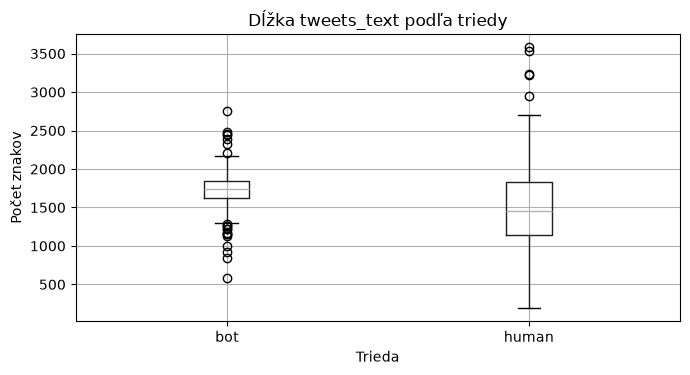

In [7]:
cresci["tweets_length"] = cresci["tweets_text"].str.len()
display(cresci.groupby(cresci_label_col)["tweets_length"].describe().round(1))

cresci.boxplot(column="tweets_length", by=cresci_label_col, figsize=(7, 4))
plt.title("Dĺžka tweets_text podľa triedy"); plt.suptitle("")
plt.xlabel("Trieda"); plt.ylabel("Počet znakov")
plt.tight_layout(); plt.show()

# ČASŤ B – Unmasking the Imposters (AI texty)

## 8. Načítanie

In [8]:
if not UNMASKING_FILE.exists():
    raise FileNotFoundError(f"Nenašiel sa {UNMASKING_FILE}. Najskôr vytvor unmasking_clean.csv.")

unmasking = pd.read_csv(UNMASKING_FILE)
unmasking_label_col = "label_name" if "label_name" in unmasking.columns else "label"
unmasking["text"] = unmasking["text"].fillna("").astype(str)

def norm(t):
    return re.sub(r"\s+", " ", str(t).lower().strip())

if "text_norm" not in unmasking.columns:
    unmasking["text_norm"] = unmasking["text"].map(norm)

print("Rozmer datasetu:", unmasking.shape)
print("Stĺpce:", unmasking.columns.tolist())
print("Modely:", sorted(unmasking["model"].unique()))
print("Splity:", sorted(unmasking["split"].unique()))
print("Prázdne texty:", (unmasking["text"].str.strip() == "").sum())
display(unmasking.head(3))

Rozmer datasetu: (79176, 7)
Stĺpce: ['text', 'label', 'model', 'split', 'label_name', 'text_length', 'text_norm']
Modely: ['Hermes-2-Pro-Llama-3-8B', 'Meta-Llama-3-8B-Instruct', 'Mistral-7B-Instruct-v0.2', 'OpenHermes-2.5-Mistral-7B', 'Qwen2-7B-Instruct', 'dolphin-2.8-mistral-7b-v02', 'dolphin-2.9-llama3-8b', 'dolphin-2.9.2-qwen2-7b', 'gpt4o']
Splity: ['test', 'train', 'val']
Prázdne texty: 0


,text,label,model,split,label_name,text_length,text_norm
0,@USER use the F word as much as you need to . ...,0,Hermes-2-Pro-Llama-3-8B,test,human,74,@user use the f word as much as you need to . ...
1,Sometimes before going to bed you just feel ov...,1,Hermes-2-Pro-Llama-3-8B,test,ai,157,sometimes before going to bed you just feel ov...
2,"Lmboo , using my nephew for meme",0,Hermes-2-Pro-Llama-3-8B,test,human,32,"lmboo , using my nephew for meme"


## 9. Počty textov podľa modelu, splitu a triedy

label_name                          ai  human
model                      split             
Hermes-2-Pro-Llama-3-8B    test    443    443
                           train  3544   3508
                           val     443    441
Meta-Llama-3-8B-Instruct   test    443    443
                           train  3539   3508
                           val     443    441
Mistral-7B-Instruct-v0.2   test    443    443
                           train  3541   3509
                           val     443    441
OpenHermes-2.5-Mistral-7B  test    443    443
                           train  3414   3445
                           val     438    439
Qwen2-7B-Instruct          test    443    443
                           train  3538   3509
                           val     442    441
dolphin-2.8-mistral-7b-v02 test    443    443
                           train  3542   3509
                           val     443    441
dolphin-2.9-llama3-8b      test    443    443
                           train  3542   3509
                           val     443    441
dolphin-2.9.2-qwen2-7b     test    443    443
                           train  3539   3509
                           val     442    441
gpt4o                      test    443    443
                           train  3541   3509
                           val     443    441

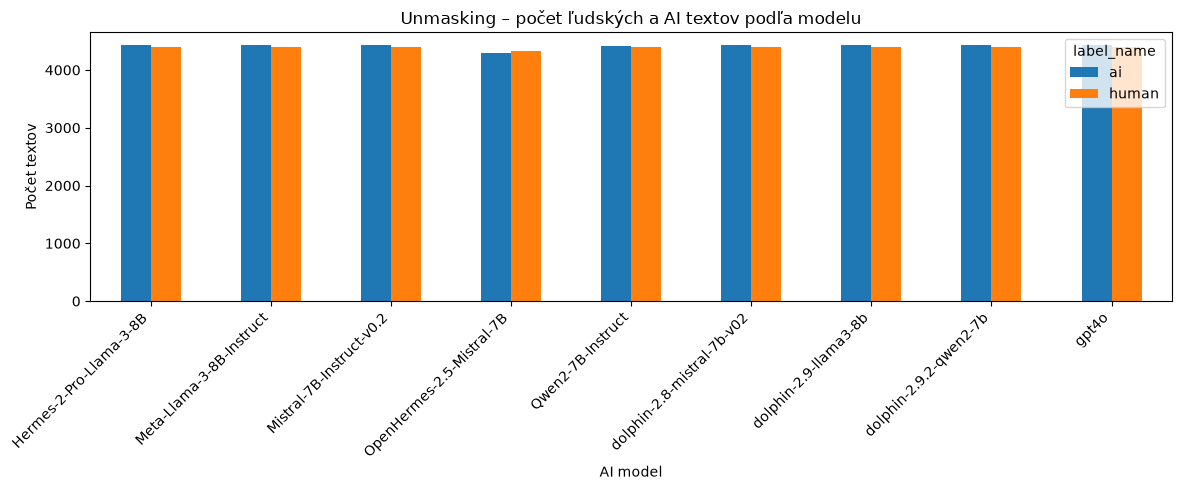

In [9]:
pivot_counts = unmasking.pivot_table(
    index=["model", "split"], columns=unmasking_label_col,
    values="text", aggfunc="count", fill_value=0)
display(pivot_counts)

model_class_counts = unmasking.groupby(["model", unmasking_label_col]).size().unstack(fill_value=0)
ax = model_class_counts.plot(kind="bar", figsize=(12, 5))
ax.set_title("Unmasking – počet ľudských a AI textov podľa modelu")
ax.set_xlabel("AI model"); ax.set_ylabel("Počet textov")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

## 10. Dĺžka textov

count   mean   std   min   25%    50%  \
model                      label_name                                           
Hermes-2-Pro-Llama-3-8B    ai          4430.0   91.5  41.7  10.0  59.0   90.0   
                           human       4392.0   87.8  38.0  10.0  57.0   89.0   
Meta-Llama-3-8B-Instruct   ai          4425.0   76.7  39.2  10.0  46.0   74.0   
                           human       4392.0   87.8  38.0  10.0  57.0   89.0   
Mistral-7B-Instruct-v0.2   ai          4427.0   93.0  39.3  10.0  61.0   91.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   
OpenHermes-2.5-Mistral-7B  ai          4295.0   88.0  38.9  10.0  56.0   88.0   
                           human       4327.0   87.8  38.0  10.0  57.0   89.0   
Qwen2-7B-Instruct          ai          4423.0   78.9  40.0  10.0  46.0   77.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   
dolphin-2.8-mistral-7b-v02 ai          4428.0   89.8  41.6  10.0  57.0   88.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   
dolphin-2.9-llama3-8b      ai          4428.0   87.3  42.5  10.0  55.0   85.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   
dolphin-2.9.2-qwen2-7b     ai          4424.0   89.3  42.1  10.0  56.0   88.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   
gpt4o                      ai          4427.0  106.5  43.0  13.0  74.0  108.0   
                           human       4393.0   87.7  38.1  10.0  57.0   89.0   

                                         75%    max  
model                      label_name                
Hermes-2-Pro-Llama-3-8B    ai          123.0  300.0  
                           human       120.0  342.0  
Meta-Llama-3-8B-Instruct   ai          106.0  419.0  
                           human       120.0  342.0  
Mistral-7B-Instruct-v0.2   ai          124.0  256.0  
                           human       120.0  342.0  
OpenHermes-2.5-Mistral-7B  ai          120.0  252.0  
                           human       120.0  342.0  
Qwen2-7B-Instruct          ai          109.0  359.0  
                           human       120.0  342.0  
dolphin-2.8-mistral-7b-v02 ai          121.0  302.0  
                           human       120.0  342.0  
dolphin-2.9-llama3-8b      ai          118.0  684.0  
                           human       120.0  342.0  
dolphin-2.9.2-qwen2-7b     ai          122.0  340.0  
                           human       120.0  342.0  
gpt4o                      ai          137.0  788.0  
                           human       120.0  342.0

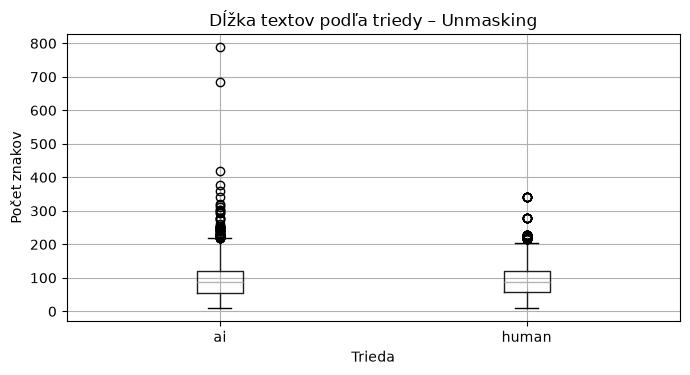

In [10]:
unmasking["text_length"] = unmasking["text"].str.len()
display(unmasking.groupby(["model", unmasking_label_col])["text_length"].describe().round(1))

unmasking.boxplot(column="text_length", by=unmasking_label_col, figsize=(7, 4))
plt.title("Dĺžka textov podľa triedy – Unmasking"); plt.suptitle("")
plt.xlabel("Trieda"); plt.ylabel("Počet znakov")
plt.tight_layout(); plt.show()

## 11. Kontrola leaku po vyčistení

Prvé dve hodnoty nižšie majú byť **0**. Ľudské texty sa opakujú naprieč modelmi (to je v poriadku), ale nesmú sa dostať do rôznych splitov.

In [11]:
dup_in_split = unmasking.duplicated(["model", "split", "text_norm"]).sum()
n_splits = unmasking.groupby("text_norm")["split"].nunique()
texts_in_many_splits = (n_splits > 1).sum()

print("Duplicity v rámci modelu a splitu:", dup_in_split)
print("Texty vyskytujúce sa vo viac než jednom splite:", texts_in_many_splits)

# Sú ľudské texty rovnaké vo všetkých modeloch pre každý split?
human = unmasking[unmasking[unmasking_label_col] == "human"]
per_split = human.groupby(["split", "model"])["text_norm"].apply(frozenset)
same = {s: per_split[s].nunique() == 1 for s in human["split"].unique()}
print("Rovnaká množina ľudských textov vo všetkých modeloch (po splitoch):", same)

Duplicity v rámci modelu a splitu: 0
Texty vyskytujúce sa vo viac než jednom splite: 0
Rovnaká množina ľudských textov vo všetkých modeloch (po splitoch): {'test': True, 'train': False, 'val': False}


## 12. Zhrnutie

Po spustení si poznač:
- Cresci-17: počet účtov a pomer bot/human, rozdiel dĺžky `tweets_text` medzi triedami,
- ktoré stĺpce majú v tabuľke z časti 5 výrazný rozdiel (tie nepoužívať ako príznaky),
- Unmasking: počty textov pre každý model a split, vyváženosť tried,
- kontrola leaku z časti 11 (obe čísla 0).

Ďalší krok: `02_baseline_bot_metadata.ipynb`.